# Task 3.1 — Incisos (c) y (d): diagrama de equilibrios e histéresis

**Grupo 3 | Parámetro:** $b=0.58$.

Modelo: $\dot{x}=f(x;a)=a-bx+\frac{x^2}{1+x^2}$. En equilibrio, $a=g(x)=bx-\frac{x^2}{1+x^2}$.

Este notebook desarrolla el diagrama de equilibrios, verifica la estabilidad y simula un barrido ascendente y descendente de la carga. El desarrollo algebraico de (a) y (b) se hace por separado a mano. Ejecutar las celdas en orden.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.integrate import solve_ivp

GRUPO = 3
b = 0.52 + 0.03 * ((GRUPO - 1) % 3)

def g(x):
    return b * x - x**2 / (1 + x**2)

def gp(x):
    return b - 2 * x / (1 + x**2)**2

def f(t, x, a):
    return a - b * x + x**2 / (1 + x**2)

print(f'Grupo {GRUPO} | b = {b:.2f}')

Grupo 3 | b = 0.58


## Puntos de referencia calculados numéricamente

Los puntos de pliegue cumplen $g'(x)=0$. El máximo y mínimo locales de $g$ corresponden, respectivamente, al umbral de colapso y al de recuperación.

In [2]:
x_peak = 1 / np.sqrt(3)  # máximo de 2x/(1+x²)^2, para x ≥ 0
x_col = brentq(gp, 0.0, x_peak)
x_rec = brentq(gp, x_peak, 2.0)
a_col, a_rec = g(x_col), g(x_rec)

assert a_col > a_rec
print(f'Colapso:      x = {x_col:.6f}, a_col = {a_col:.6f}')
print(f'Recuperación: x = {x_rec:.6f}, a_rec = {a_rec:.6f}')
print(f'Ancho biestable: {a_col-a_rec:.6f}')

Colapso:      x = 0.379594, a_col = 0.094220
Recuperación: x = 0.834431, a_rec = 0.073497
Ancho biestable: 0.020723


## (c) Diagrama de equilibrios

Se grafica $x^*$ en el eje **vertical** y $a$ en el **horizontal**. Según la demostración, $g'(x^*)>0$ implica rama estable y $g'(x^*)<0$ rama inestable. Las líneas continuas indican estabilidad, las discontinuas inestabilidad; en los puntos críticos $g'=0$.

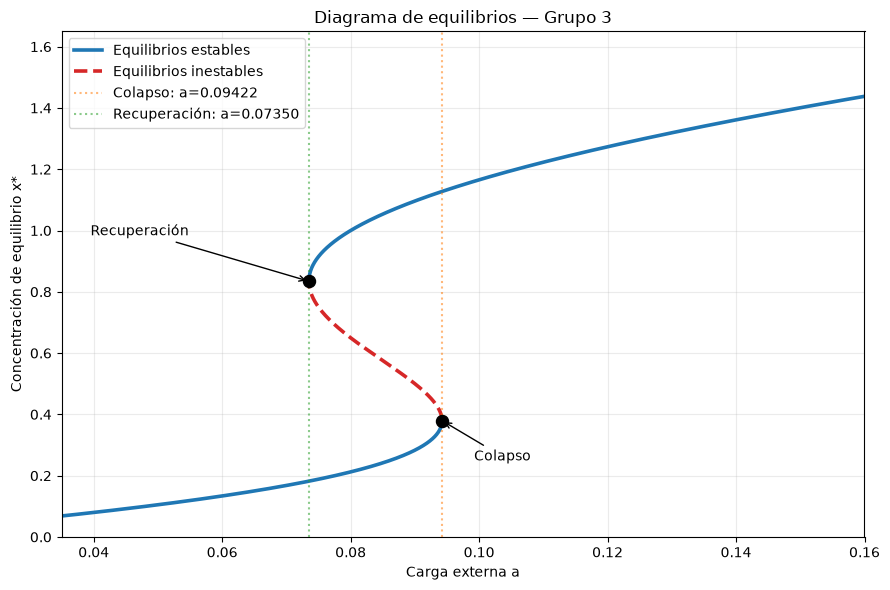

In [3]:
x_grid = np.linspace(0.0, 1.65, 4500)
a_grid = g(x_grid)
stable = gp(x_grid) > 0
unstable = gp(x_grid) < 0

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(np.ma.masked_where(~stable, a_grid), np.ma.masked_where(~stable, x_grid),
        color='tab:blue', lw=2.6, label='Equilibrios estables')
ax.plot(np.ma.masked_where(~unstable, a_grid), np.ma.masked_where(~unstable, x_grid),
        color='tab:red', lw=2.6, ls='--', label='Equilibrios inestables')
ax.scatter([a_col, a_rec], [x_col, x_rec], s=75, color='black', zorder=5)
ax.axvline(a_col, color='tab:orange', alpha=.55, ls=':', label=f'Colapso: a={a_col:.5f}')
ax.axvline(a_rec, color='tab:green', alpha=.55, ls=':', label=f'Recuperación: a={a_rec:.5f}')
ax.annotate('Colapso', (a_col, x_col), (a_col+.005, x_col-.13), arrowprops={'arrowstyle':'->'})
ax.annotate('Recuperación', (a_rec, x_rec), (a_rec-.034, x_rec+.15), arrowprops={'arrowstyle':'->'})
ax.set(xlabel='Carga externa a', ylabel='Concentración de equilibrio x*',
       title='Diagrama de equilibrios — Grupo 3', xlim=(0.035, 0.16), ylim=(0, 1.65))
ax.grid(alpha=.25)
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('task3_equilibrios.png', dpi=180, bbox_inches='tight')
plt.show()

### Interpretación del inciso (c)

Para $a<a_{\mathrm{rec}}$ existe una rama estable de concentración baja. Entre $a_{\mathrm{rec}}$ y $a_{\mathrm{col}}$ coexisten dos ramas estables separadas por una inestable. Para $a>a_{\mathrm{col}}$ queda la rama estable de concentración alta. Los puntos de pliegue marcan el límite de las ramas correspondientes.

## (d) Simulación determinista del barrido de carga

Se incrementa $a$ desde una carga baja hasta superar el colapso y luego se disminuye hasta cruzar la recuperación. En **cada nivel de carga** se integra la EDO, usando el estado final del nivel anterior como condición inicial. Esto modela un barrido cuasiestático por escalones pequeños.

El umbral de salto se detecta cuando la trayectoria cruza un valor intermedio $x_{\mathrm{umbral}}=(x_{\mathrm{col}}+x_{\mathrm{rec}})/2$; este criterio operativo puede producir ligeras diferencias respecto al punto matemático de pliegue. Se puede aumentar `TIEMPO_POR_PASO` o `N_PASOS` para acercarse al límite cuasiestático.

In [4]:
A_MIN, A_MAX = 0.045, 0.125
N_PASOS = 401
TIEMPO_POR_PASO = 160.0

subida = np.linspace(A_MIN, A_MAX, N_PASOS)
bajada = np.linspace(A_MAX, A_MIN, N_PASOS)

def barrido(valores_a, x_inicial):
    trayectoria = []
    x_actual = float(x_inicial)
    for a in valores_a:
        sol = solve_ivp(lambda t, y: f(t, y, a),
                        (0, TIEMPO_POR_PASO), [x_actual],
                        method='RK45', rtol=1e-8, atol=1e-10)
        if not sol.success:
            raise RuntimeError(sol.message)
        x_actual = sol.y[0, -1]
        trayectoria.append(x_actual)
    return np.asarray(trayectoria)

# Inicialización: equilibrio bajo en A_MIN; continuación sin reiniciar entre pasos.
x0 = brentq(lambda x: g(x)-A_MIN, 0.0, x_col)
x_subida = barrido(subida, x0)
x_bajada = barrido(bajada, x_subida[-1])

umbral = (x_col + x_rec) / 2
idx_col = np.flatnonzero((x_subida[:-1] < umbral) & (x_subida[1:] >= umbral))
idx_rec = np.flatnonzero((x_bajada[:-1] > umbral) & (x_bajada[1:] <= umbral))
if len(idx_col) != 1 or len(idx_rec) != 1:
    raise RuntimeError('No se detectó exactamente un salto por dirección; ajustar A_MIN, A_MAX, tiempo o resolución.')
i_col = int(idx_col[0] + 1)
i_rec = int(idx_rec[0] + 1)
a_col_sim, a_rec_sim = subida[i_col], bajada[i_rec]
print(f'Salto en subida:     a ≈ {a_col_sim:.6f} (teórico {a_col:.6f})')
print(f'Salto en bajada:    a ≈ {a_rec_sim:.6f} (teórico {a_rec:.6f})')
print(f'Diferencia subida:  {a_col_sim-a_col:+.6f}')
print(f'Diferencia bajada:  {a_rec_sim-a_rec:+.6f}')
print(f'Histéresis simulada: {a_col_sim-a_rec_sim:.6f}')

Salto en subida:     a ≈ 0.094600 (teórico 0.094220)
Salto en bajada:    a ≈ 0.073000 (teórico 0.073497)
Diferencia subida:  +0.000380
Diferencia bajada:  -0.000497
Histéresis simulada: 0.021600


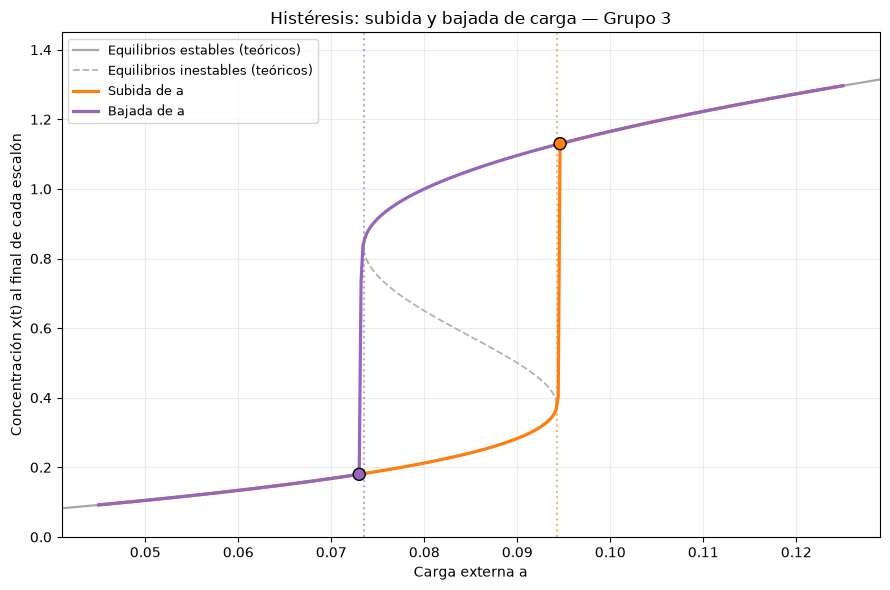

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(np.ma.masked_where(~stable, a_grid), np.ma.masked_where(~stable, x_grid),
        color='0.65', lw=1.6, label='Equilibrios estables (teóricos)')
ax.plot(np.ma.masked_where(~unstable, a_grid), np.ma.masked_where(~unstable, x_grid),
        color='0.7', ls='--', lw=1.3, label='Equilibrios inestables (teóricos)')
ax.plot(subida, x_subida, color='tab:orange', lw=2.3, label='Subida de a')
ax.plot(bajada, x_bajada, color='tab:purple', lw=2.3, label='Bajada de a')
ax.scatter([a_col_sim, a_rec_sim], [x_subida[i_col], x_bajada[i_rec]],
           c=['tab:orange','tab:purple'], s=75, edgecolors='black', zorder=6)
ax.axvline(a_col, color='tab:orange', ls=':', alpha=.6)
ax.axvline(a_rec, color='tab:purple', ls=':', alpha=.6)
ax.set(xlabel='Carga externa a', ylabel='Concentración x(t) al final de cada escalón',
       title='Histéresis: subida y bajada de carga — Grupo 3',
       xlim=(A_MIN-.004,A_MAX+.004), ylim=(0,1.45))
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=.25)
plt.tight_layout()
plt.savefig('task3_histeresis.png', dpi=180, bbox_inches='tight')
plt.show()

### Análisis del inciso (d)

El sistema sigue la rama de concentración baja durante la subida, hasta aproximarse al pliegue $a_{\mathrm{col}}$ y saltar a una rama de concentración alta. Al bajar la carga, **no recorre el mismo camino**: permanece en la rama alta hasta acercarse a $a_{\mathrm{rec}}$ y luego retorna a la rama baja. Este ciclo constituye la histéresis.

**Diferencias entre simulación y teoría.** Los valores teóricos son los pliegues para equilibrio estático. Los valores medidos con la simulación dependen de los incrementos $\Delta a$, del tiempo de relajación por paso y del criterio empleado para identificar el salto. Cerca de un pliegue el sistema tarda más en relajarse (ralentización crítica), por lo que un barrido a velocidad finita puede retrasar el salto: típicamente $a_{\mathrm{col,sim}}>a_{\mathrm{col}}$ y $a_{\mathrm{rec,sim}}<a_{\mathrm{rec}}$. Para comprobarlo, repetir con más pasos y mayor tiempo por paso. Los resultados precisos se imprimen en la celda anterior.